# PedalPulse: exploratory data analysis

Data: release `data-v2`, file `station_hours_dev.parquet` and the daily system totals, restricted to local dates up to 2025-06-30. The holdout file is not read. Counts are pickups per cohort station and UTC hour; hours with `status = inactive` and the repeated 01:00 hour of fall-back nights (`dst_repeat`) are left out of the averages unless stated otherwise. Weather in this notebook is observed ERA5 weather and is only descriptive.


In [1]:
import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pedalpulse import config

RELEASE = config.RELEASE_DIR
FIGURES = config.FIGURES_DIR
FIGURES.mkdir(parents=True, exist_ok=True)
EDA_END = pd.Timestamp(config.EDA_END)

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
con = duckdb.connect()
con.execute("SET TimeZone = 'UTC'")
con.execute("SET enable_progress_bar = false")
DEV = f"read_parquet('{(RELEASE / 'station_hours_dev.parquet').as_posix()}')"
CAL = f"read_parquet('{(RELEASE / 'calendar.parquet').as_posix()}')"
# The repeated 01:00 hour of fall-back nights has no pickups by construction; treat it like inactive hours.
EDA = f"""(SELECT * EXCLUDE (status), CASE WHEN status = 'observed' AND hour_utc IN (
            SELECT hour_utc FROM {CAL} WHERE hour_local = 1 AND local_hours_in_day = 25 AND utc_offset_h = -5)
          THEN 'dst_repeat' ELSE status END AS status
       FROM {DEV} WHERE date_local <= DATE '{config.EDA_END}')"""

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIGURES / f"{name}.png", bbox_inches="tight")
    plt.show()

stations = pd.read_parquet(RELEASE / "stations.parquet")
cohort = stations[stations["is_cohort"]]
calendar = pd.read_parquet(RELEASE / "calendar.parquet")
daily = pd.read_parquet(RELEASE / "daily_system.parquet")
daily["date_local"] = pd.to_datetime(daily["date_local"])
daily = daily[daily["date_local"] <= EDA_END]
rows = con.execute(f"SELECT count(*), count(DISTINCT station_id), min(date_local), max(date_local) FROM {EDA}").fetchone()
print(f"EDA window: {rows[2]} to {rows[3]}, {rows[0]:,} station-hours, {rows[1]:,} cohort stations")


EDA window: 2023-01-01 to 2025-06-30, 42,547,145 station-hours, 2,072 cohort stations


## 1. Daily trips and trend

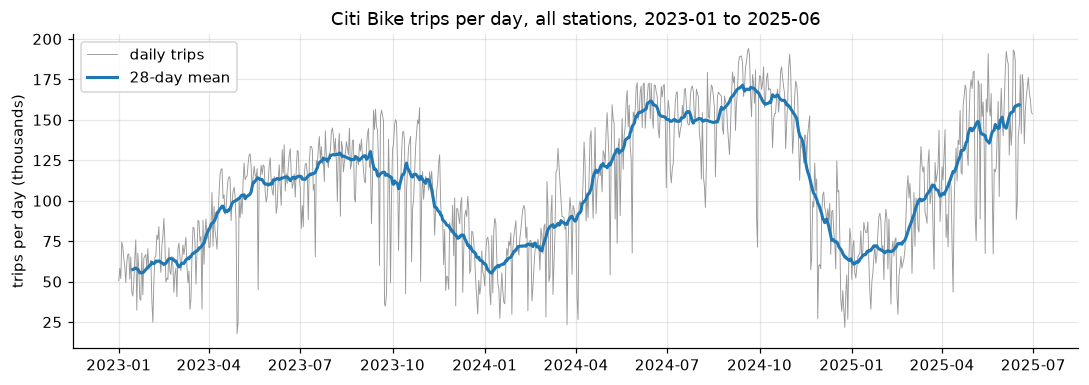

                   sum      mean       max
date_local                                
2023        35088923.0   96134.0  157537.0
2024        44273171.0  120965.0  194122.0
2025        20126700.0  111197.0  193200.0
mean per day in June to August (2025: June only): {2023: 120335.0, 2024: 153288.0, 2025: 158575.0}
date_local   trips
2023-04-29 17757.0
2024-12-25 21565.0
2024-03-23 23396.0


In [2]:
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(daily["date_local"], daily["trips"] / 1000, lw=0.6, color="0.6", label="daily trips")
ax.plot(daily["date_local"], daily["trips"].rolling(28, center=True).mean() / 1000, lw=2, color="C0", label="28-day mean")
ax.set_ylabel("trips per day (thousands)")
ax.set_title("Citi Bike trips per day, all stations, 2023-01 to 2025-06")
ax.legend(loc="upper left")
save(fig, "01_daily_trips")
by_year = daily.groupby(daily["date_local"].dt.year)["trips"].agg(["sum", "mean", "max"])
summer = daily[daily["date_local"].dt.month.isin([6, 7, 8])].groupby(daily["date_local"].dt.year)["trips"].mean()
print(by_year.round(0)); print("mean per day in June to August (2025: June only):", summer.round(0).to_dict())
print(daily.nsmallest(3, "trips")[["date_local", "trips"]].to_string(index=False))


The system had 35.1 million cleaned trips in 2023 and 44.3 million in 2024. The mean day from June to August rose from 120,000 trips in 2023 to 153,000 in 2024; June 2025, the last month in the EDA window, averaged 159,000. Most of the growth happened between 2023 and 2024. The lowest day, 2023-04-29 with 17,757 trips, had 28.8 mm of rain (ERA5); the figure covers all stations, not only the cohort.

## 2. Coverage, zeros and inactive hours

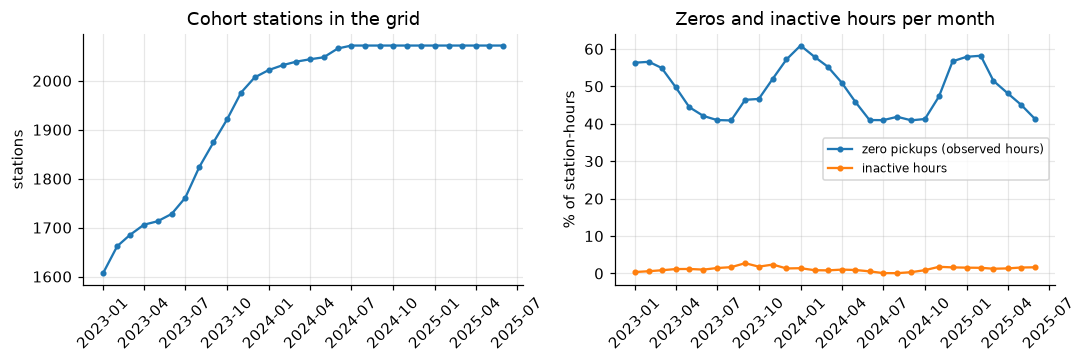

        month  stations_in_grid  inactive_share  zero_share
0  2023-01-01              1607          0.0038       0.563
5  2023-06-01              1728          0.0102       0.421
11 2023-12-01              2007          0.0133       0.572
17 2024-06-01              2066          0.0056       0.410
23 2024-12-01              2072          0.0162       0.567
29 2025-06-01              2072          0.0164       0.412


inactive share 0.0120, zero share of observed hours 0.490


In [3]:
monthly = con.execute(f"""
    SELECT date_trunc('month', date_local) AS month,
           count(DISTINCT station_id) AS stations_in_grid,
           avg((status = 'inactive')::INT) AS inactive_share,
           avg((pickups = 0)::INT) FILTER (WHERE status = 'observed') AS zero_share
    FROM {EDA} GROUP BY 1 ORDER BY 1
""").df()
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(monthly["month"], monthly["stations_in_grid"], marker="o", ms=3)
ax[0].set_title("Cohort stations in the grid")
ax[0].set_ylabel("stations")
ax[1].plot(monthly["month"], monthly["zero_share"] * 100, marker="o", ms=3, label="zero pickups (observed hours)")
ax[1].plot(monthly["month"], monthly["inactive_share"] * 100, marker="o", ms=3, label="inactive hours")
ax[1].set_ylabel("% of station-hours")
ax[1].set_title("Zeros and inactive hours per month")
ax[1].legend(fontsize=8)
for a in ax:
    a.tick_params(axis="x", rotation=45)
save(fig, "02_coverage")
print(monthly.assign(zero_share=lambda d: d.zero_share.round(3), inactive_share=lambda d: d.inactive_share.round(4)).iloc[[0, 5, 11, 17, 23, 29]])
totals = con.execute(f"SELECT avg((status='inactive')::INT), avg((pickups=0)::INT) FILTER (WHERE status='observed') FROM {EDA}").fetchone()
print(f"inactive share {totals[0]:.4f}, zero share of observed hours {totals[1]:.3f}")


The number of cohort stations in the grid grows from 1,607 in January 2023 to all 2,072 from July 2024 (the last cohort station opened on 19 July 2024), because each station enters the grid with its first trip. Of the observed station-hours, 49.0 % have zero pickups, about 58 % in winter (December to February) and 41 % in summer (June to August). Inactive hours are 1.2 % of the EDA window and peak at 2.7 % in September 2023; the rule cannot tell a closure from a station that moved to a new ID.

## 3. Distribution of hourly pickups

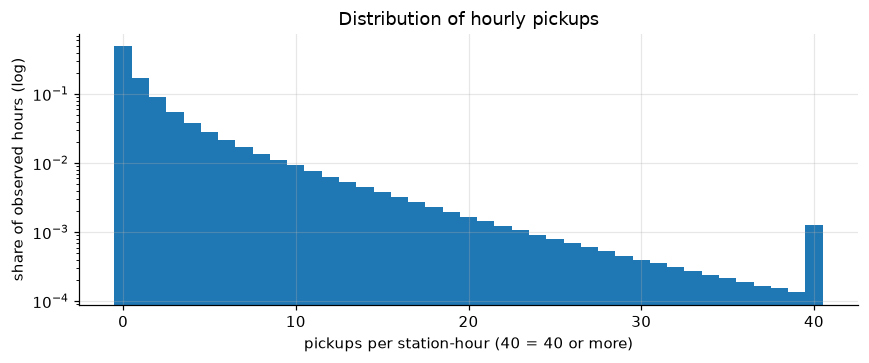

mean 2.26, variance 20.49, quantiles 50/90/99 [1.0, 7.0, 22.0], max 191
   pickups         n     share
0        0  20577174  0.489533
1        1   7297609  0.173611
2        2   3786247  0.090075
3        3   2347611  0.055850


In [4]:
dist = con.execute(f"SELECT pickups, count(*) AS n FROM {EDA} WHERE status = 'observed' GROUP BY 1 ORDER BY 1").df()
dist["share"] = dist["n"] / dist["n"].sum()
fig, ax = plt.subplots(figsize=(8, 3.4))
binned = dist.assign(bin=dist["pickups"].clip(upper=40)).groupby("bin")["share"].sum()
ax.bar(binned.index, binned.values, width=1.0, color="C0")
ax.set_yscale("log")
ax.set_xlabel("pickups per station-hour (40 = 40 or more)")
ax.set_ylabel("share of observed hours (log)")
ax.set_title("Distribution of hourly pickups")
save(fig, "03_count_distribution")
stats = con.execute(f"""SELECT avg(pickups), var_samp(pickups), quantile_cont(pickups, [0.5, 0.9, 0.99]), max(pickups)
                        FROM {EDA} WHERE status = 'observed'""").fetchone()
print(f"mean {stats[0]:.2f}, variance {stats[1]:.2f}, quantiles 50/90/99 {stats[2]}, max {stats[3]}")
print(dist.head(4))


Half of the observed station-hours have zero pickups and 17 % have exactly one. The mean is 2.26 and the variance 20.49, so the counts are strongly overdispersed compared with a Poisson distribution. The 99th percentile is 22 pickups and the maximum 191.

## 4. Daily profile: working days and days off

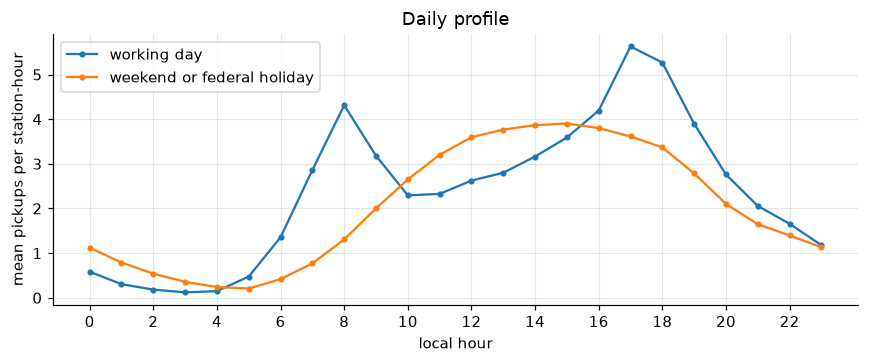

day_off     False  True 
hour_local              
3            0.12   0.36
8            4.31   1.31
12           2.63   3.60
15           3.59   3.90
17           5.63   3.61
18           5.27   3.37
22           1.66   1.40


In [5]:
profile = con.execute(f"""
    SELECT s.hour_local, c.is_weekend OR c.is_federal_holiday AS day_off, avg(pickups) AS mean_pickups
    FROM {EDA} s JOIN read_parquet('{(RELEASE / 'calendar.parquet').as_posix()}') c USING (hour_utc)
    WHERE status = 'observed' GROUP BY ALL ORDER BY ALL
""").df()
fig, ax = plt.subplots(figsize=(8, 3.4))
for flag, label in ((False, "working day"), (True, "weekend or federal holiday")):
    part = profile[profile["day_off"] == flag]
    ax.plot(part["hour_local"], part["mean_pickups"], marker="o", ms=3, label=label)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel("local hour")
ax.set_ylabel("mean pickups per station-hour")
ax.set_title("Daily profile")
ax.legend()
save(fig, "04_daily_profile")
print(profile.pivot(index="hour_local", columns="day_off", values="mean_pickups").round(2).loc[[3, 8, 12, 15, 17, 18, 22]])


Working days have two peaks, 4.3 pickups per station-hour at 08:00 and 5.6 at 17:00. Weekends and federal holidays have no morning peak and a flat plateau from about 12:00 to 17:00 at 3.6 to 3.9. At night days off are busier, 0.36 against 0.12 at 03:00.

## 5. Weekday by hour

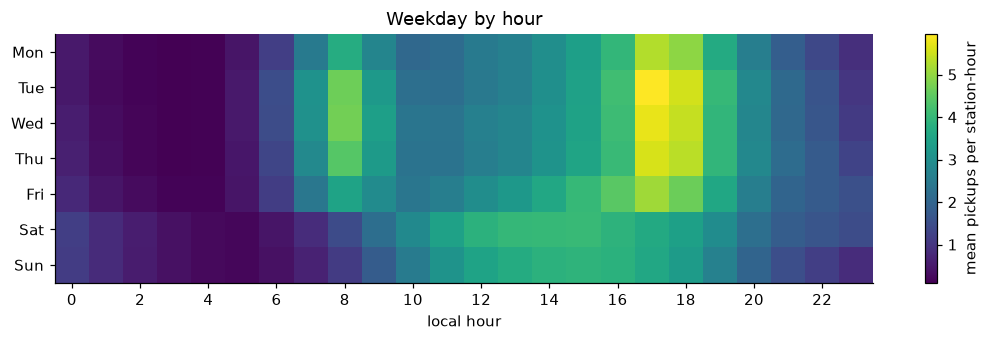

hour_local    8     17    18
weekday                     
0           3.73  5.27  4.95
1           4.65  5.95  5.56
2           4.70  5.76  5.44
3           4.41  5.60  5.35
4           3.50  5.11  4.63
5           1.44  3.66  3.44
6           1.12  3.60  3.32


In [6]:
heat = con.execute(f"""
    SELECT c.weekday, s.hour_local, avg(pickups) AS mean_pickups
    FROM {EDA} s JOIN read_parquet('{(RELEASE / 'calendar.parquet').as_posix()}') c USING (hour_utc)
    WHERE status = 'observed' GROUP BY ALL
""").df().pivot(index="weekday", columns="hour_local", values="mean_pickups")
fig, ax = plt.subplots(figsize=(10, 3.2))
image = ax.imshow(heat.values, aspect="auto", cmap="viridis")
ax.set_yticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
ax.set_xticks(range(0, 24, 2), range(0, 24, 2))
ax.set_xlabel("local hour")
ax.grid(False)
fig.colorbar(image, ax=ax, label="mean pickups per station-hour")
ax.set_title("Weekday by hour")
save(fig, "05_heatmap_weekday_hour")
print(heat.round(2)[[8, 17, 18]])


The evening peak at 17:00 is highest from Tuesday to Thursday (5.6 to 6.0) and lower on Monday and Friday. The morning peak shows the same pattern, 4.7 on Tuesday and Wednesday against 3.7 on Monday and 3.5 on Friday. Holidays are not removed here, and several federal holidays fall on Mondays.

## 6. Stations by volume

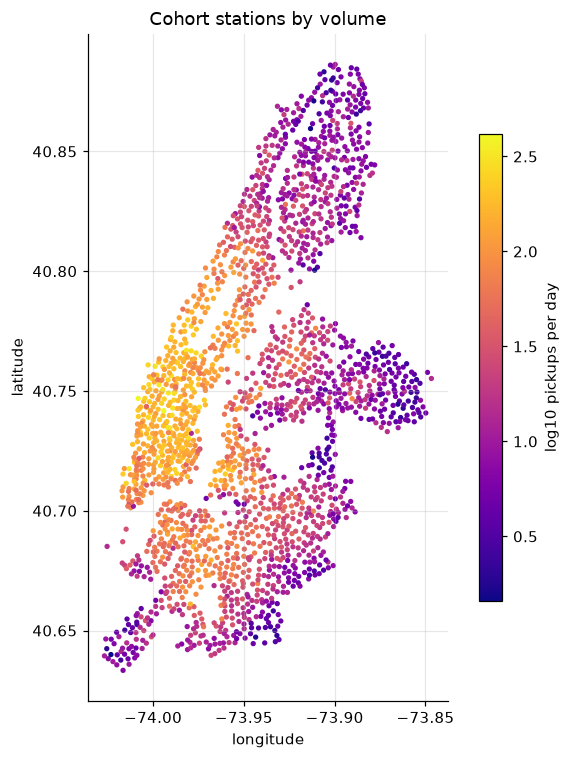

count    2072.0
mean       52.9
std        61.4
min         1.5
25%         9.9
50%        24.8
75%        76.6
max       414.7
Name: pickups_per_day, dtype: float64
                          name    borough  pickups_per_day
41             W 21 St & 6 Ave  Manhattan            415.0
707   Pier 61 at Chelsea Piers  Manhattan            391.0
314      West St & Chambers St  Manhattan            338.0
879         Broadway & W 58 St  Manhattan            338.0
1217   University Pl & E 14 St  Manhattan            335.0


In [7]:
volume = con.execute(f"""
    SELECT station_id, sum(pickups) AS pickups, sum(pickups) / count(DISTINCT date_local) AS pickups_per_day
    FROM {EDA} WHERE status = 'observed' GROUP BY 1
""").df().merge(cohort[["station_id", "name", "lat", "lng", "borough"]], on="station_id")
fig, ax = plt.subplots(figsize=(6, 7))
points = ax.scatter(volume["lng"], volume["lat"], c=np.log10(volume["pickups_per_day"].clip(lower=1)), s=6, cmap="plasma")
ax.set_aspect(1 / np.cos(np.radians(40.73)))
ax.set_xlabel("longitude"); ax.set_ylabel("latitude")
fig.colorbar(points, ax=ax, label="log10 pickups per day", shrink=0.7)
ax.set_title("Cohort stations by volume")
save(fig, "06_station_map")
print(volume["pickups_per_day"].describe().round(1))
print(volume.nlargest(5, "pickups_per_day")[["name", "borough", "pickups_per_day"]].round(0))


Demand is concentrated in Midtown and Lower Manhattan; all five busiest stations are in Manhattan, led by W 21 St & 6 Ave with 415 pickups per day. The median cohort station has 24.8 pickups per day and the mean is 52.9, so a few large stations carry much of the volume. Values are averages over each station's observed days in the EDA window.

## 7. Boroughs

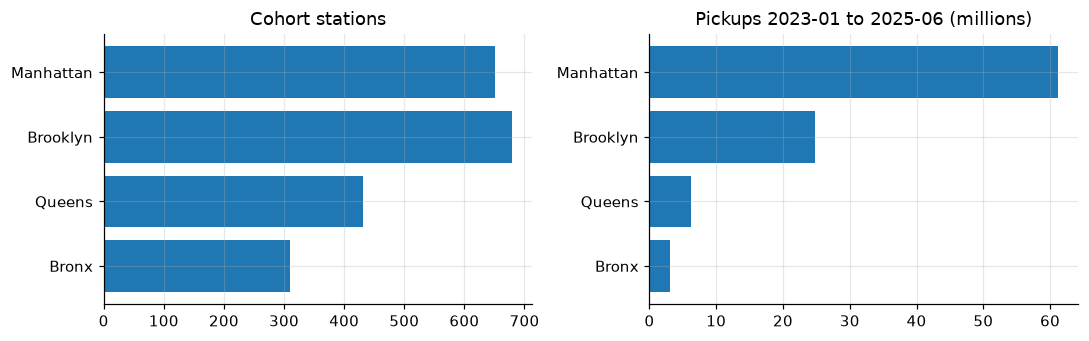

           stations     pickups  median_station  share_pickups
borough                                                       
Bronx           310   3055567.0           9.449          0.032
Queens          432   6181396.0          10.677          0.065
Brooklyn        679  24794880.0          31.004          0.261
Manhattan       651  61122243.0         100.566          0.642


In [8]:
by_borough = volume.groupby("borough").agg(stations=("station_id", "size"), pickups=("pickups", "sum"),
                                           median_station=("pickups_per_day", "median")).sort_values("pickups")
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].barh(by_borough.index, by_borough["stations"]); ax[0].set_title("Cohort stations")
ax[1].barh(by_borough.index, by_borough["pickups"] / 1e6); ax[1].set_title("Pickups 2023-01 to 2025-06 (millions)")
save(fig, "07_boroughs")
by_borough["share_pickups"] = by_borough["pickups"] / by_borough["pickups"].sum()
print(by_borough.round(3))


Manhattan has 651 of the 2,072 cohort stations (31 %) but 64 % of the pickups, Brooklyn has 679 stations and 26 %, Queens 432 and 6.5 %, the Bronx 310 and 3.2 %. The median Manhattan station has 100.6 pickups per day, the median Bronx station 9.4. No station in the data lies on Staten Island.

## 8. Stations by demand class

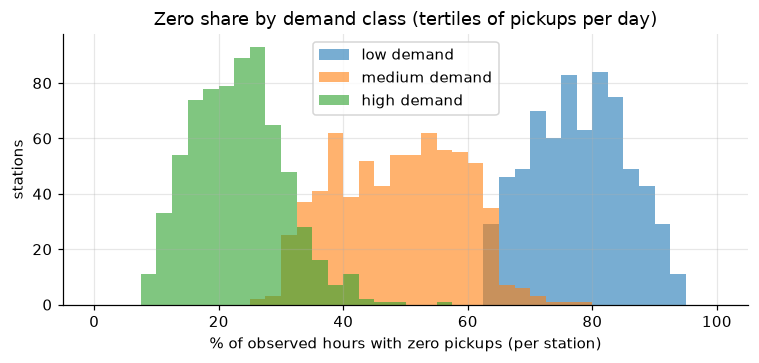

              stations  max_pickups_per_day  median_zero_share
demand_class                                                  
low                691               13.873              0.779
medium             690               53.213              0.494
high               691              414.651              0.230


In [9]:
volume["demand_class"] = pd.qcut(volume["pickups_per_day"], 3, labels=["low", "medium", "high"])
classes = con.execute(f"""SELECT station_id, avg((pickups = 0)::INT) AS zero_share FROM {EDA}
                          WHERE status = 'observed' GROUP BY 1""").df().merge(volume, on="station_id")
fig, ax = plt.subplots(figsize=(7, 3.4))
for label, part in classes.groupby("demand_class", observed=True):
    ax.hist(part["zero_share"] * 100, bins=40, range=(0, 100), alpha=0.6, label=f"{label} demand")
ax.set_xlabel("% of observed hours with zero pickups (per station)")
ax.set_ylabel("stations")
ax.set_title("Zero share by demand class (tertiles of pickups per day)")
ax.legend()
save(fig, "08_demand_classes")
print(classes.groupby("demand_class", observed=True).agg(stations=("station_id", "size"),
      max_pickups_per_day=("pickups_per_day", "max"), median_zero_share=("zero_share", "median")).round(3))


Splitting the cohort into thirds by pickups per day gives a low class up to 13.9 pickups per day and a high class from 53.2. In the low class the median station has zero pickups in 78 % of its observed hours, in the high class in 23 %. The share of zero hours thus differs by a factor of more than three between the classes.

## 9. Temperature and precipitation (observed weather, descriptive)

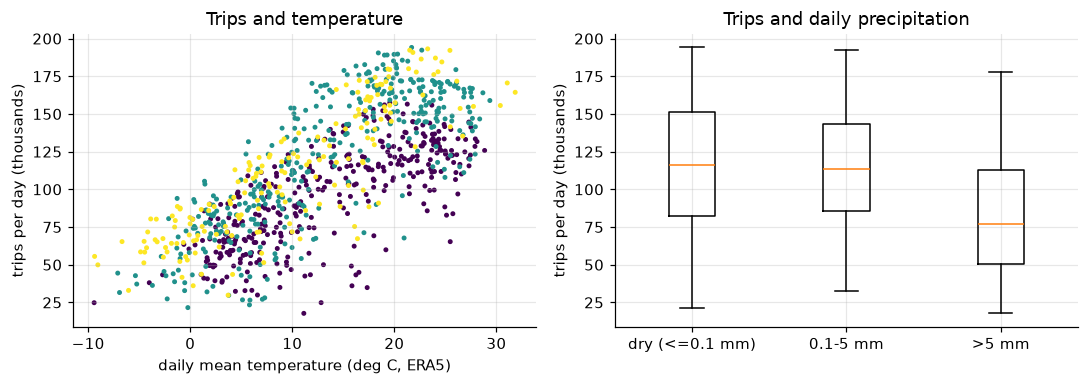

                size    median
rain                          
dry (<=0.1 mm)   496  116016.0
0.1-5 mm         241  113821.0
>5 mm            175   76925.0
temperature
(-20, 0]     58431.0
(0, 10]      77008.0
(10, 20]    128197.0
(20, 30]    141640.0
(30, 40]    164378.0
Name: trips, dtype: float64
correlation trips/temperature: 0.74
date_local   trips  temperature  precipitation
2023-04-29 17757.0         11.1           28.8
2024-12-25 21565.0         -0.2            0.0
2024-03-23 23396.0          5.8           57.3


In [10]:
observed = pd.read_parquet(RELEASE / "weather_observed.parquet")
observed["date_local"] = observed["hour_utc"].dt.tz_convert(config.TIMEZONE).dt.tz_localize(None).dt.normalize()
weather_day = observed.groupby("date_local").agg(temperature=("temperature_2m", "mean"), precipitation=("precipitation", "sum"))
days = daily.merge(weather_day, left_on="date_local", right_index=True)
days["rain"] = pd.cut(days["precipitation"], [-0.1, 0.1, 5, 1000], labels=["dry (<=0.1 mm)", "0.1-5 mm", ">5 mm"])
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
ax[0].scatter(days["temperature"], days["trips"] / 1000, s=5, c=days["date_local"].dt.year, cmap="viridis")
ax[0].set_xlabel("daily mean temperature (deg C, ERA5)"); ax[0].set_ylabel("trips per day (thousands)")
ax[0].set_title("Trips and temperature")
groups = [days.loc[days["rain"] == label, "trips"] / 1000 for label in days["rain"].cat.categories]
ax[1].boxplot(groups, tick_labels=list(days["rain"].cat.categories))
ax[1].set_ylabel("trips per day (thousands)"); ax[1].set_title("Trips and daily precipitation")
save(fig, "09_weather")
print(days.groupby("rain", observed=True)["trips"].agg(["size", "median"]).round(0))
print(days.groupby(pd.cut(days["temperature"], [-20, 0, 10, 20, 30, 40]), observed=True)["trips"].median().round(0))
print("correlation trips/temperature:", round(days["trips"].corr(days["temperature"]), 2))
print(days.nsmallest(3, "trips")[["date_local", "trips", "temperature", "precipitation"]].to_string(index=False, float_format="%.1f"))


Daily trips and daily mean temperature correlate at 0.74; the median day has 58,000 trips at or below 0 degrees C and 164,000 above 30 degrees C. Days with more than 5 mm of rain have a median of 77,000 trips against 116,000 on dry days (at most 0.1 mm). Temperature and season move together, so these figures do not separate the two effects, and the weather is observed ERA5 data that a day-ahead forecast would not have.

## 10. Holidays

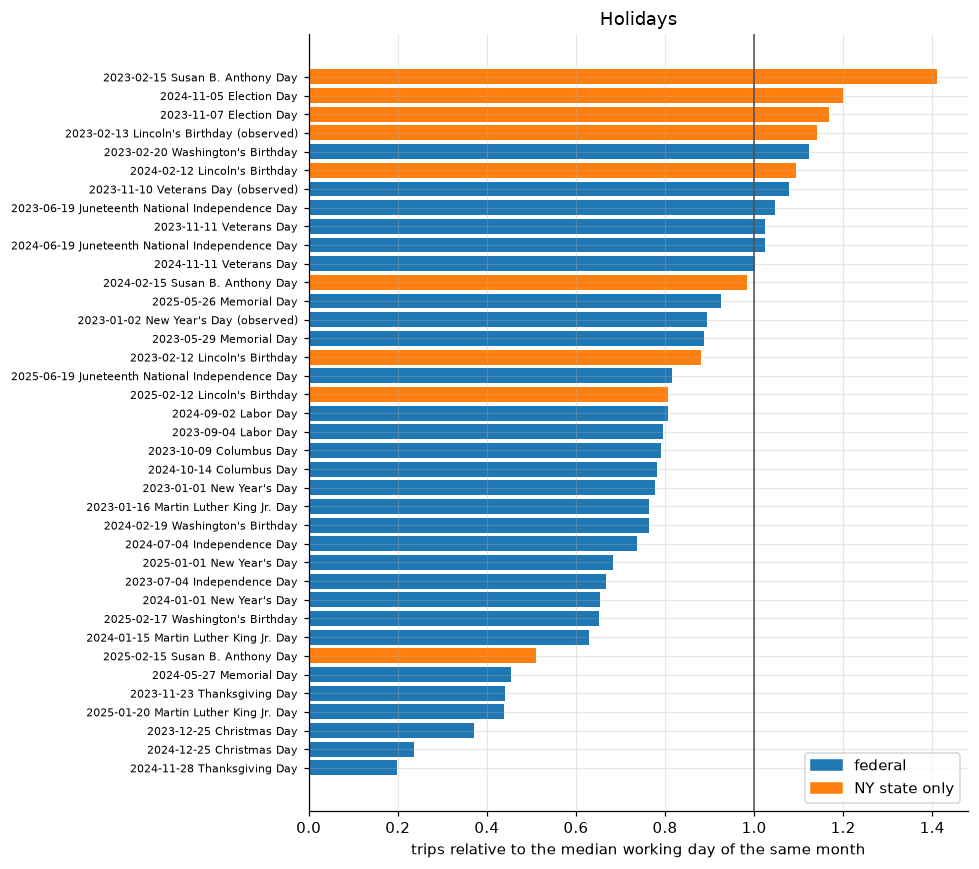

                 size    median
day_type                       
NY state only       9   75443.0
federal holiday    29   70879.0
weekend           257   99977.0
working day       617  115043.0
kind
NY state only    1.09
federal          0.78
Name: ratio, dtype: float64
date_local               holiday_name    kind  ratio
2024-11-28           Thanksgiving Day federal   0.20
2024-12-25              Christmas Day federal   0.24
2023-12-25              Christmas Day federal   0.37
2025-01-20 Martin Luther King Jr. Day federal   0.44
date_local                  holiday_name          kind  ratio
2023-02-13 Lincoln's Birthday (observed) NY state only   1.14
2023-11-07                  Election Day NY state only   1.17
2024-11-05                  Election Day NY state only   1.20
2023-02-15          Susan B. Anthony Day NY state only   1.41


In [11]:
day_types = calendar.drop_duplicates("date_local")[["date_local", "weekday", "is_weekend", "is_holiday", "holiday_name", "is_federal_holiday"]]
day_types["date_local"] = pd.to_datetime(day_types["date_local"])
days = days.merge(day_types, on="date_local")
days["day_type"] = np.where(days["is_federal_holiday"], "federal holiday",
                    np.where(days["is_holiday"], "NY state only", np.where(days["is_weekend"], "weekend", "working day")))
summary = days.groupby("day_type")["trips"].agg(["size", "median"])
ratio = days[days["is_holiday"]].copy()
ratio["kind"] = np.where(ratio["is_federal_holiday"], "federal", "NY state only")
ratio["same_month_working_median"] = ratio["date_local"].map(
    lambda d: days.loc[(days["day_type"] == "working day") & (days["date_local"].dt.to_period("M") == d.to_period("M")), "trips"].median())
ratio["ratio"] = ratio["trips"] / ratio["same_month_working_median"]
fig, ax = plt.subplots(figsize=(9, 8))
order = ratio.sort_values("ratio")
ax.barh(order["date_local"].dt.strftime("%Y-%m-%d") + " " + order["holiday_name"], order["ratio"],
        color=np.where(order["kind"] == "federal", "C0", "C1"))
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color="C0"), plt.Rectangle((0, 0), 1, 1, color="C1")],
          labels=["federal", "NY state only"], loc="lower right")
ax.axvline(1, color="0.3", lw=1)
ax.set_xlabel("trips relative to the median working day of the same month")
ax.set_title("Holidays")
ax.tick_params(axis="y", labelsize=7.5)
save(fig, "10_holidays")
print(summary.round(0)); print(ratio.groupby("kind")["ratio"].median().round(2))
columns = ["date_local", "holiday_name", "kind", "ratio"]
print(order[columns].head(4).to_string(index=False, float_format="%.2f")); print(order[columns].tail(4).to_string(index=False, float_format="%.2f"))


On federal holidays the median day has 70,900 trips, against 115,000 on working days and 100,000 on weekends; relative to the median working day of the same month the median federal holiday reaches 0.78. Thanksgiving 2024 (0.20) and Christmas 2024 (0.24) are the lowest. Holidays that only New York State observes, such as Lincoln's Birthday and Election Day, are at 1.09 and behave like working days, which matters because `is_holiday` includes them.

## 11. E-bike and member share

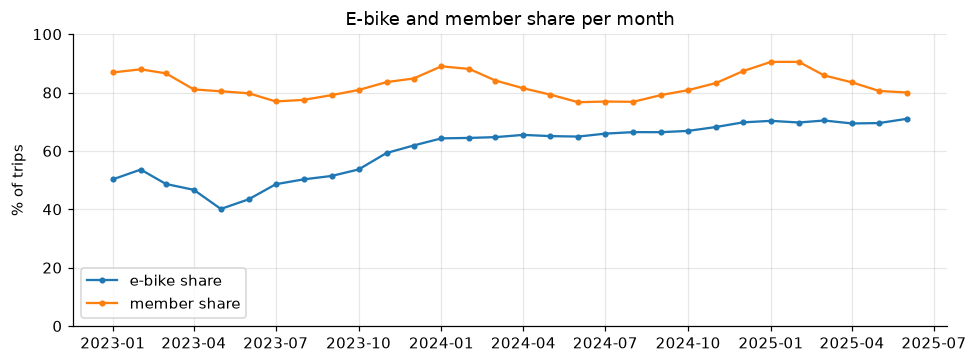

            ebike_share  member_share
date_local                           
2023-01           0.503         0.869
2023-07           0.486         0.769
2024-01           0.643         0.890
2024-07           0.659         0.769
2025-01           0.703         0.905
2025-06           0.710         0.800


In [12]:
monthly_mix = daily.groupby(daily["date_local"].dt.to_period("M"))[["trips", "ebike_trips", "member_trips"]].sum()
monthly_mix["ebike_share"] = monthly_mix["ebike_trips"] / monthly_mix["trips"]
monthly_mix["member_share"] = monthly_mix["member_trips"] / monthly_mix["trips"]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(monthly_mix.index.to_timestamp(), monthly_mix["ebike_share"] * 100, marker="o", ms=3, label="e-bike share")
ax.plot(monthly_mix.index.to_timestamp(), monthly_mix["member_share"] * 100, marker="o", ms=3, label="member share")
ax.set_ylabel("% of trips"); ax.set_ylim(0, 100); ax.legend()
ax.set_title("E-bike and member share per month")
save(fig, "11_ebike_member")
print(monthly_mix[["ebike_share", "member_share"]].round(3).iloc[[0, 6, 12, 18, 24, -1]])


The e-bike share rose from 50 % of trips in January 2023 to 66 % in July 2024 and 71 % in June 2025. Members make up 87 to 91 % of trips in January and 77 to 80 % in summer, when more casual riders use the system. Both shares are computed over all stations.